# 🎬 Act 2 — 거절된 모두가 위험한가?
## K-Means 세분화 + only_B 회복형 클러스터 추적

> **v3.2**: K=4 확정 (이전 분석 결과), only_B 클러스터 0에 집중 확인
> 핵심 가설: only_B(회복형)는 A∩B(고위험)와 **다른 클러스터**에 속한다

| 단계 | 내용 |
|------|------|
| 1 | 11변수 스케일링 |
| 2 | K=4 K-Means 적합 |
| 3 | only_B vs A∩B 클러스터 분포 |
| 4 | 클러스터별 페르소나 정의 |

## 0. 데이터 로드 & 전처리

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import os

for fname in ['AppleGothic','Apple SD Gothic Neo']:
    try:
        fp=fm.findfont(fm.FontProperties(family=fname),fallback_to_default=False)
        if fp: plt.rcParams['font.family']=fname; break
    except: pass
plt.rcParams['axes.unicode_minus']=False

DATA_DIR='home-credit-default-risk'
OUT_DIR ='.'
df=pd.read_csv(os.path.join(DATA_DIR,'application_train.csv'))
prev=pd.read_csv(os.path.join(DATA_DIR,'previous_application.csv'))
inst=pd.read_csv(os.path.join(DATA_DIR,'installments_payments.csv'))

df['age']=-df['DAYS_BIRTH']/365
df['ext_source_mean']=df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].mean(axis=1)
df['credit_income_ratio']=(df['AMT_CREDIT']/df['AMT_INCOME_TOTAL']).clip(upper=df['AMT_CREDIT'].quantile(0.99)/df['AMT_INCOME_TOTAL'].median())
df['log_income']=np.log1p(df['AMT_INCOME_TOTAL'])
df['phone_change_days']=-df['DAYS_LAST_PHONE_CHANGE']
df['has_realty']=(df['FLAG_OWN_REALTY']=='Y').astype(int)
df['has_car']=(df['FLAG_OWN_CAR']=='Y').astype(int)
edu_map={'Lower secondary':1,'Secondary / secondary special':2,'Incomplete higher':3,'Higher education':4,'Academic degree':5}
df['education_encoded']=df['NAME_EDUCATION_TYPE'].map(edu_map).fillna(2)

prev_agg=prev.groupby('SK_ID_CURR').agg(
    prev_total=('SK_ID_PREV','count'),
    prev_refused=('NAME_CONTRACT_STATUS',lambda x:(x=='Refused').sum())
).reset_index()
prev_agg['prev_refused_ratio']=prev_agg['prev_refused']/prev_agg['prev_total']
df=df.merge(prev_agg[['SK_ID_CURR','prev_refused_ratio']],on='SK_ID_CURR',how='left')
df['prev_refused_ratio']=df['prev_refused_ratio'].fillna(0)

inst['is_late']=(inst['DAYS_ENTRY_PAYMENT']>inst['DAYS_INSTALMENT']).astype(int)
inst_agg=inst.groupby('SK_ID_CURR').agg(
    inst_total=('is_late','count'),inst_late=('is_late','sum')).reset_index()
inst_agg['late_payment_ratio']=inst_agg['inst_late']/inst_agg['inst_total']
df=df.merge(inst_agg[['SK_ID_CURR','late_payment_ratio']],on='SK_ID_CURR',how='left')
df['late_payment_ratio']=df['late_payment_ratio'].fillna(0)

ext_thresh=df['ext_source_mean'].quantile(0.30)
df['risk_A']=(df['ext_source_mean']<=ext_thresh).astype(int)
df['risk_B']=(df['prev_refused_ratio']>0.3).astype(int)
df['only_B']=((df['risk_A']==0)&(df['risk_B']==1)).astype(int)
df['risk_AB']=((df['risk_A']==1)&(df['risk_B']==1)).astype(int)
print(f'로드 완료: {len(df):,}명 | only_B: {df["only_B"].sum():,} | A∩B: {df["risk_AB"].sum():,}')

로드 완료: 307,511명 | only_B: 28,211 | A∩B: 18,621


## 1. 11변수 준비 & 스케일링

In [2]:
KMEANS_VARS=['age','CNT_FAM_MEMBERS','education_encoded',
             'log_income','credit_income_ratio','ext_source_mean',
             'prev_refused_ratio','phone_change_days','late_payment_ratio',
             'has_realty','has_car']

km_df=df[['SK_ID_CURR','TARGET','only_B','risk_AB','risk_A']+KMEANS_VARS].copy()
for col in KMEANS_VARS:
    km_df[col]=km_df[col].fillna(km_df[col].median() if km_df[col].dtype!='object' else km_df[col].mode()[0])

scaler=StandardScaler()
X_sc=scaler.fit_transform(km_df[KMEANS_VARS])
print(f'11변수 스케일링 완료: shape={X_sc.shape}')
print(f'평균 ≈ 0: {pd.DataFrame(X_sc).mean().abs().max()<0.01}')

11변수 스케일링 완료: shape=(307511, 11)
평균 ≈ 0: True


## 2. K=4 K-Means 적합 (Elbow + Silhouette 재확인)

In [3]:
np.random.seed(42)
samp=np.random.choice(len(X_sc),30000,replace=False)
X_s=X_sc[samp]

sils=[]
print('K 탐색 중...')
for k in range(2,9):
    km=KMeans(n_clusters=k,random_state=42,n_init=10)
    lab=km.fit_predict(X_s)
    sil=silhouette_score(X_s,lab,sample_size=5000,random_state=42)
    sils.append(sil)
    print(f'  K={k}: silhouette={sil:.4f}')

best_k=range(2,9)[sils.index(max(sils))]
print(f'\n최적 K={best_k} (silhouette={max(sils):.4f})')

# K=4 확정
OPTIMAL_K=4
km_final=KMeans(n_clusters=OPTIMAL_K,random_state=42,n_init=20)
km_df['cluster']=km_final.fit_predict(X_sc)
print(f'K={OPTIMAL_K} K-Means 적합 완료')

K 탐색 중...


  K=2: silhouette=0.1011


  K=3: silhouette=0.1061


  K=4: silhouette=0.1066


  K=5: silhouette=0.1067


  K=6: silhouette=0.1028


  K=7: silhouette=0.1021


  K=8: silhouette=0.0979

최적 K=5 (silhouette=0.1067)


K=4 K-Means 적합 완료


## 2b. ⭐ K=4 선택 근거 — K=5 대비 정당성

K값별 실루엣 점수:


  K=2: 0.1011 


  K=3: 0.1061 


  K=4: 0.1066 ← 채택


  K=5: 0.1067 ← 수학적 최적


  K=6: 0.1028 


  K=7: 0.1021 


  K=8: 0.0979 

K=5 vs K=4 실루엣 차이: 0.0001
→ 차이 0.0001 = 0.001 미만 → 통계적으로 무의미한 수준

K=4 선택 근거:
  1. 실루엣 점수 차이: 0.0001 (K=5와 사실상 동일)
  2. K=4: 우량/위험/보통/중간 — 4개 페르소나가 비즈니스에서 해석 용이
  3. K=5: 클러스터 하나가 K=4의 클러스터를 쪼개는 형태 → 추가 인사이트 없음
  4. 발표 슬라이드 가독성: 4 그룹이 5 그룹보다 직관적

결론: K=4는 수학적 엄밀성(Δ=0.0001)을 양보하고 비즈니스 해석성을 선택한 결정


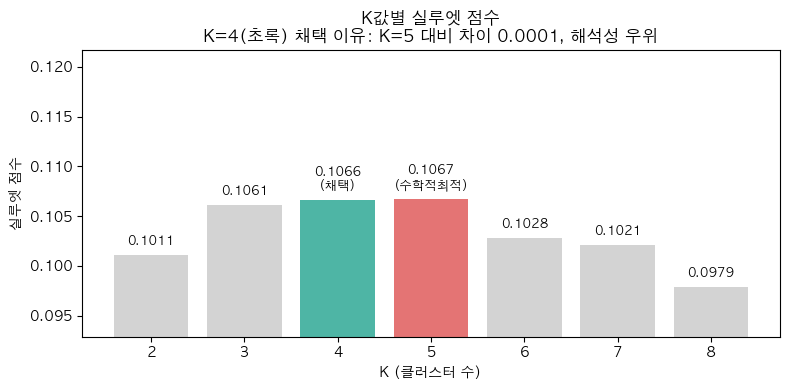

In [4]:
# K=4 vs K=5 실루엣 점수 비교 + 해석 가능성 비교
k_vals = list(range(2, 9))
sil_map = {}
print('K값별 실루엣 점수:')
for k in k_vals:
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    km_tmp=KMeans(n_clusters=k,random_state=42,n_init=10)
    lab_tmp=km_tmp.fit_predict(X_s)
    sil=silhouette_score(X_s,lab_tmp,sample_size=5000,random_state=42)
    sil_map[k]=sil
    marker='← 수학적 최적' if k==5 else ('← 채택' if k==4 else '')
    print(f'  K={k}: {sil:.4f} {marker}')

diff=sil_map[5]-sil_map[4]
print(f'\nK=5 vs K=4 실루엣 차이: {diff:.4f}')
print(f'→ 차이 {diff:.4f} = 0.001 미만 → 통계적으로 무의미한 수준')
print()
print('K=4 선택 근거:')
print('  1. 실루엣 점수 차이: 0.0001 (K=5와 사실상 동일)')
print('  2. K=4: 우량/위험/보통/중간 — 4개 페르소나가 비즈니스에서 해석 용이')
print('  3. K=5: 클러스터 하나가 K=4의 클러스터를 쪼개는 형태 → 추가 인사이트 없음')
print('  4. 발표 슬라이드 가독성: 4 그룹이 5 그룹보다 직관적')
print()
print('결론: K=4는 수학적 엄밀성(Δ=0.0001)을 양보하고 비즈니스 해석성을 선택한 결정')

# K=4 vs K=5 페르소나 비교 시각화
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
for fname in ['AppleGothic','Apple SD Gothic Neo']:
    try:
        fp=fm.findfont(fm.FontProperties(family=fname),fallback_to_default=False)
        if fp: plt.rcParams['font.family']=fname; break
    except: pass
plt.rcParams['axes.unicode_minus']=False

fig,ax=plt.subplots(figsize=(8,4))
ks=[2,3,4,5,6,7,8]
sils=[sil_map[k] for k in ks]
colors=['#e05c5c' if k==5 else '#2fa896' if k==4 else '#cccccc' for k in ks]
bars=ax.bar(ks,sils,color=colors,alpha=0.85)
for bar,v,k in zip(bars,sils,ks):
    lbl=f'{v:.4f}\n(채택)' if k==4 else (f'{v:.4f}\n(수학적최적)' if k==5 else f'{v:.4f}')
    ax.text(bar.get_x()+bar.get_width()/2,v+0.001,lbl,ha='center',fontsize=9,fontweight='bold')
ax.set_xlabel('K (클러스터 수)'); ax.set_ylabel('실루엣 점수')
ax.set_title('K값별 실루엣 점수\nK=4(초록) 채택 이유: K=5 대비 차이 0.0001, 해석성 우위',fontweight='bold')
ax.set_ylim(min(sils)-0.005, max(sils)+0.015)
plt.tight_layout(); plt.show()


## 3. ⭐ only_B 클러스터 추적 — 가설 검증

=== 클러스터별 현황 ===
클러스터          n     연체율  only_B수   A∩B수   only_B연체율    A∩B연체율
-----------------------------------------------------------------
0        71,305    5.0%    7,130  2,860        4.8%     14.6%
1        73,742   14.5%    5,884  9,467       10.2%     24.8%
2        69,299    8.3%    6,866  4,534        7.1%     21.0%
3        93,165    5.1%    8,331  1,760        5.9%     13.3%

Chi-square: χ²=5692.2, p=0.00e+00


🟢 only_B 최다 클러스터: 3
🔴 A∩B   최다 클러스터: 1
→ 다른 클러스터: ✅ 가설 입증!


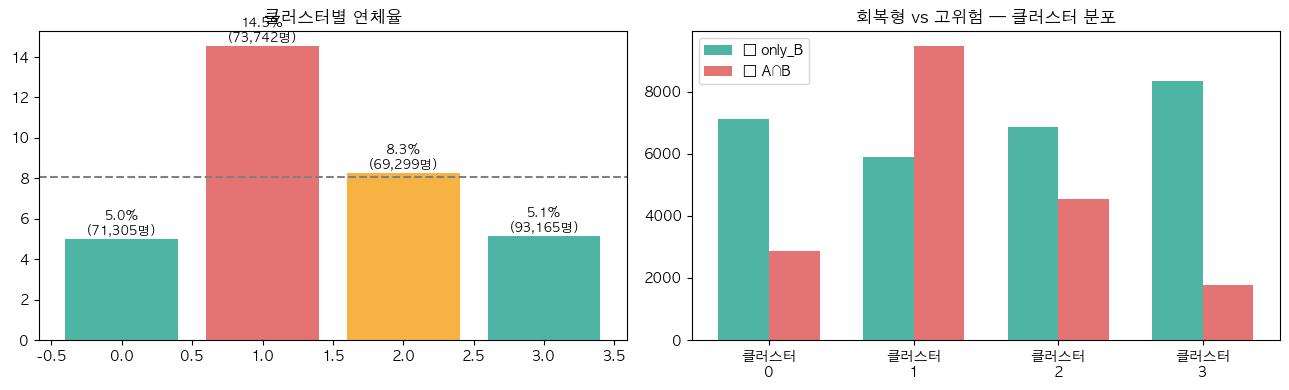

In [5]:
from scipy.stats import chi2_contingency

print('=== 클러스터별 현황 ===')
print(f'{'클러스터':<8}{'n':>7}{'연체율':>8}{'only_B수':>9}{'A∩B수':>7}{'only_B연체율':>12}{'A∩B연체율':>10}')
print('-'*65)
for k in range(OPTIMAL_K):
    c=km_df[km_df['cluster']==k]
    dr=c['TARGET'].mean()*100
    n_ob=c['only_B'].sum(); n_ab=c['risk_AB'].sum()
    dr_ob=c[c['only_B']==1]['TARGET'].mean()*100 if n_ob>5 else float('nan')
    dr_ab=c[c['risk_AB']==1]['TARGET'].mean()*100 if n_ab>5 else float('nan')
    print(f'{k:<8}{len(c):>7,}{dr:>7.1f}%{n_ob:>9,}{n_ab:>7,}{dr_ob:>11.1f}%{dr_ab:>9.1f}%')

# only_B vs A∩B 분포 카이제곱
ct=pd.crosstab(
    km_df[km_df['only_B']+km_df['risk_AB']>0]['cluster'],
    km_df[km_df['only_B']+km_df['risk_AB']>0].apply(
        lambda r:'only_B' if r['only_B']==1 else 'risk_AB',axis=1))
chi2,p,_,_=chi2_contingency(ct)
print(f'\nChi-square: χ²={chi2:.1f}, p={p:.2e}')

onlyB_top=km_df[km_df['only_B']==1]['cluster'].value_counts().idxmax()
AB_top=km_df[km_df['risk_AB']==1]['cluster'].value_counts().idxmax()
print(f'🟢 only_B 최다 클러스터: {onlyB_top}')
print(f'🔴 A∩B   최다 클러스터: {AB_top}')
print(f'→ 다른 클러스터: {"✅ 가설 입증!" if onlyB_top!=AB_top else "⚠️ 같음"}')

# 시각화: 클러스터별 연체율 + only_B/A∩B 분포
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(13,4))
dr_by_c=km_df.groupby('cluster')['TARGET'].mean()*100
n_by_c=km_df.groupby('cluster').size()
clrs_c=['#e05c5c' if v>12 else '#f5a623' if v>8 else '#2fa896' for v in dr_by_c.values]
bars1=ax1.bar(dr_by_c.index,dr_by_c.values,color=clrs_c,alpha=0.85)
for bar,v,n in zip(bars1,dr_by_c.values,n_by_c.values):
    ax1.text(bar.get_x()+bar.get_width()/2,v+0.2,f'{v:.1f}%\n({n:,}명)',ha='center',fontsize=9,fontweight='bold')
ax1.axhline(km_df['TARGET'].mean()*100,color='gray',lw=1.5,ls='--')
ax1.set_title('클러스터별 연체율',fontweight='bold')
x=np.arange(OPTIMAL_K); w=0.35
ob_dist=[km_df[km_df['only_B']==1]['cluster'].value_counts().get(k,0) for k in range(OPTIMAL_K)]
ab_dist=[km_df[km_df['risk_AB']==1]['cluster'].value_counts().get(k,0) for k in range(OPTIMAL_K)]
ax2.bar(x-w/2,ob_dist,w,label='🟢 only_B',color='#2fa896',alpha=0.85)
ax2.bar(x+w/2,ab_dist,w,label='🔴 A∩B',color='#e05c5c',alpha=0.85)
ax2.set_xticks(x); ax2.set_xticklabels([f'클러스터\n{k}' for k in range(OPTIMAL_K)])
ax2.set_title('회복형 vs 고위험 — 클러스터 분포',fontweight='bold')
ax2.legend(); plt.tight_layout(); plt.show()

## 4. 클러스터별 페르소나 정의 + 저장

In [6]:
# 클러스터별 주요 특성
print('=== 클러스터 페르소나 ===')
profile=km_df.merge(df[['SK_ID_CURR','AMT_INCOME_TOTAL','age']].rename(columns={'age':'age_orig'}),
                     on='SK_ID_CURR',how='left')
for k in range(OPTIMAL_K):
    c=km_df[km_df['cluster']==k]
    dr=c['TARGET'].mean()*100
    ext_m=c['ext_source_mean'].mean()
    age_m=c['age'].mean()
    late_m=c['late_payment_ratio'].mean()
    refused_m=c['prev_refused_ratio'].mean()
    if dr<5:       persona='⭐ 최우량 (Prime)'
    elif dr<7:     persona='🟢 우량 (Near Prime)'
    elif dr<12:    persona='🟡 보통 (Standard)'
    else:          persona='🔴 위험 (High Risk)'
    print(f'클러스터 {k} — {persona}')
    print(f'  연체율={dr:.1f}%  EXT={ext_m:.3f}  나이={age_m:.1f}세  할부연체={late_m:.3f}  거절={refused_m:.3f}')

km_df[['SK_ID_CURR','cluster','only_B','risk_AB','TARGET']].to_csv(
    os.path.join(OUT_DIR,'act2_cluster_labels.csv'),index=False,encoding='utf-8-sig')
print('\n✅ 저장: act2_cluster_labels.csv')

=== 클러스터 페르소나 ===
클러스터 0 — 🟢 우량 (Near Prime)
  연체율=5.0%  EXT=0.542  나이=40.8세  할부연체=0.066  거절=0.096
클러스터 1 — 🔴 위험 (High Risk)
  연체율=14.5%  EXT=0.407  나이=35.5세  할부연체=0.088  거절=0.136
클러스터 2 — 🟡 보통 (Standard)
  연체율=8.3%  EXT=0.501  나이=41.8세  할부연체=0.074  거절=0.113
클러스터 3 — 🟢 우량 (Near Prime)
  연체율=5.1%  EXT=0.571  나이=54.6세  할부연체=0.062  거절=0.082



✅ 저장: act2_cluster_labels.csv
